# Τρία σώματα: πόσο μετρά μια μικρή αλλαγή;
Υπολογιστικό πείραμα για μαθητές — συνοδευτικό υλικό για τον «Φυσικό Κόσμο».

Εκτελέστε **Εκτέλεση όλων**. Το notebook περιέχει όλο τον κώδικα: δεν χρειάζεται να κατεβάσετε το `.py`. Δημιουργεί τον φάκελο `results` στο τρέχον περιβάλλον. Δεν αναρτά δεδομένα.

## Μοντέλο και μονάδες
Τρεις σημειακές μάζες στο επίπεδο, χωρίς εξωτερική δύναμη:
$$\ddot{\mathbf r}_i=\sum_{j\ne i}m_j\frac{\mathbf r_j-\mathbf r_i}{|\mathbf r_j-\mathbf r_i|^3}.$$
Επιλέγουμε μονάδα μάζας $M_0$, μήκους $L_0$ και χρόνου $T_0=\sqrt{L_0^3/(G M_0)}$. Οι αριθμοί του κώδικα είναι αδιάστατοι, άρα $G=1$, η μονάδα ταχύτητας είναι $L_0/T_0$ και της ενέργειας $G M_0^2/L_0$. Δεν περιγράφουμε συγκεκριμένο αστρικό σύστημα.

## Αρχικές συνθήκες
Η κλασική διάταξη Burrau έχει μάζες $(3,4,5)$ στις θέσεις $(1,3),(-2,-1),(1,-1)$ και μηδενικές ταχύτητες. Το κέντρο μάζας είναι ήδη στην αρχή. Στη λύση Β αλλάζουμε $x_1$ κατά $\epsilon=10^{-6}$ και $x_2$ κατά $-3\epsilon/4$. Έτσι και οι δύο λύσεις έχουν ακριβώς το ίδιο αρχικό κέντρο μάζας και μηδενική ολική ορμή. Η αρχική ενέργεια Α είναι $-769/60$. Η Β έχει ελαφρά διαφορετική ενέργεια: δεν επιβάλλουμε ίδιες ενεργειακές επιφάνειες.

Επιλέγουμε αυτή την ιστορικά μελετημένη διάταξη για τις διαδοχικές στενές αλληλεπιδράσεις της, όχι επειδή κάθε κίνηση τριών σωμάτων είναι χαοτική. Υπάρχουν και περιοδικές λύσεις, όπως η οκτάσχημη τροχιά ίσων μαζών.

## Τι μετράμε;
Σε κοινούς χρόνους, με σταθερές ταυτότητες σωμάτων, αφαιρούμε χωριστά το κέντρο μάζας κάθε λύσης και ορίζουμε
$$D(t)=\sqrt{\frac{\sum_i m_i|[\mathbf r_i^A-\mathbf R^A]-[\mathbf r_i^B-\mathbf R^B]|^2}{\sum_i m_i}}.$$
Αρχικά $D(0)=\sqrt{7/16}\,\epsilon$. Δεν συγκρίνουμε διαφορετικές χρονικές φάσεις, δεν περιστρέφουμε τις τροχιές και δεν αντιμεταθέτουμε σώματα. Αυτή είναι απόσταση θέσεων, όχι πλήρης απόσταση στον χώρο φάσεων.

## Αριθμητική μέθοδος και όρια
Χρησιμοποιούμε DOP853 (Runge–Kutta τάξης 8) σε τρία επίπεδα ανοχών. Οι ανοχές αφορούν τοπικές εκτιμήσεις σφάλματος, δεν εγγυώνται ισόποσο συνολικό σφάλμα. Τα 10001 σημεία εξόδου προκύπτουν από πυκνή παρεμβολή, όχι από σταθερό βήμα ολοκλήρωσης.

Δεν χρησιμοποιείται εξομάλυνση. Τρία τερματικά γεγονότα διακόπτουν την ολοκλήρωση όταν οποιαδήποτε απόσταση μειωθεί σε $10^{-3}L_0$. Δεν συνεχίζουμε μέσα από σύγκρουση και δεν συγχωνεύουμε σώματα. Το προεπιλεγμένο παράθυρο $0\le t\le15.8$ μένει πριν από την πρώτη τέτοια προσέγγιση· δοκιμή έως 20 διακόπηκε περίπου στο 15.8299. Τα γεγονότα εντοπίζονται με αλλαγή προσήμου μεταξύ βημάτων: δεν αποτελούν αυστηρή μαθηματική εγγύηση για αυθαίρετες αλλαγές των αρχικών δεδομένων. Αν αλλάξετε τη διάταξη, μειώστε το μέγιστο βήμα και επανελέγξτε τις προσεγγίσεις.

Ελέγχουμε $E=\sum m_iv_i^2/2-\sum_{i<j}m_im_j/r_{ij}$, $\mathbf P=\sum m_i\mathbf v_i$ και $L_z=\sum m_i(x_iv_{yi}-y_iv_{xi})$. Επειδή $\mathbf P(0)=0$ και $L_z(0)=0$, τα σφάλματά τους είναι απόλυτα. Η διατήρηση των ολοκληρωμάτων είναι αναγκαίος έλεγχος, αλλά μόνη της δεν αποδεικνύει ακριβή τροχιά.


In [1]:
"""Νευτώνειο πείραμα Burrau — εκτέλεση: python three_body.py."""
from pathlib import Path
import json
import platform
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

M = np.array([3., 4., 5.])
EPS = 1e-6
T_END = 15.8
R_STOP = 1e-3
PAIRS = [(0, 1), (0, 2), (1, 2)]


def center(x):
    """Αφαίρεση κέντρου μάζας από πίνακα (...,3,2)."""
    return x - np.sum(x * M[:, None], axis=-2, keepdims=True) / M.sum()


def initial(perturbed=False):
    r = np.array([[1., 3.], [-2., -1.], [1., -1.]])
    if perturbed:
        # Αντίθετες μετατοπίσεις: μηδενική μεταβολή του κέντρου μάζας.
        r[0, 0] += EPS
        r[1, 0] -= M[0] / M[1] * EPS
    return np.r_[center(r).ravel(), np.zeros(6)]


def rhs(t, y):
    r, v = y[:6].reshape(3, 2), y[6:].reshape(3, 2)
    a = np.zeros_like(r)
    for i, j in PAIRS:
        d = r[j] - r[i]
        f = d / np.linalg.norm(d)**3  # Ακριβής νόμος 1/r², χωρίς εξομάλυνση.
        a[i] += M[j] * f
        a[j] -= M[i] * f
    return np.r_[v.ravel(), a.ravel()]


def integrate(y0, rtol, atol, max_step):
    events = []
    for i, j in PAIRS:
        def close(t, y, i=i, j=j):
            r = y[:6].reshape(3, 2)
            return np.linalg.norm(r[i] - r[j]) - R_STOP
        close.terminal = True
        close.direction = -1
        events.append(close)
    sol = solve_ivp(rhs, (0, T_END), y0, method='DOP853',
                    rtol=rtol, atol=atol, max_step=max_step,
                    dense_output=True, events=events)
    if not sol.success or sol.status != 0:
        raise RuntimeError(f'Διακοπή στο t={sol.t[-1]:.12g}: {sol.message}. '
                           'Δεν επιτρέπεται εξαγωγή συμπερασμάτων πέρα από τη διακοπή.')
    return sol


def distance(a, b):
    """Μαζικά σταθμισμένη RMS απόσταση θέσεων, σε κοινό χρόνο."""
    dr = center(a[:, :6].reshape(-1, 3, 2)) - center(b[:, :6].reshape(-1, 3, 2))
    return np.sqrt(np.sum(M[None, :, None] * dr**2, axis=(1, 2)) / M.sum())


def invariants(y):
    r, v = y[:, :6].reshape(-1, 3, 2), y[:, 6:].reshape(-1, 3, 2)
    energy = np.sum(M[None, :, None] * v**2, axis=(1, 2)) / 2
    for i, j in PAIRS:
        energy -= M[i] * M[j] / np.linalg.norm(r[:, i] - r[:, j], axis=1)
    p = np.sum(M[None, :, None] * v, axis=1)
    l = np.sum(M * (r[:, :, 0]*v[:, :, 1] - r[:, :, 1]*v[:, :, 0]), axis=1)
    return energy, p, l


def diagnostics(sol, times):
    # Περιλαμβάνονται και τα προσαρμοστικά αποδεκτά βήματα.
    t = np.unique(np.r_[times, sol.t])
    y = sol.sol(t).T
    e, p, l = invariants(y)
    r = y[:, :6].reshape(-1, 3, 2)
    return dict(relative_energy_drift=float(np.max(abs(e-e[0]))/abs(e[0])),
                absolute_momentum_drift=float(np.max(np.linalg.norm(p-p[0], axis=1))),
                absolute_angular_momentum_drift=float(np.max(abs(l-l[0]))),
                com_drift=float(np.max(np.linalg.norm(np.sum(r*M[None,:,None], axis=1)/M.sum(), axis=1))),
                sampled_min_separation=float(min(np.min(np.linalg.norm(r[:,i]-r[:,j], axis=1)) for i,j in PAIRS)),
                nfev=sol.nfev, accepted_steps=len(sol.t)-1)


def run(output='results'):
    out = Path(output)
    out.mkdir(exist_ok=True, parents=True)
    times = np.linspace(0, T_END, 10001)
    settings = [('βασική', 1e-12, 1e-14, .01),
                ('αυστηρή', 1e-13, 1e-15, .005),
                ('αναφοράς', 3e-14, 3e-16, .0025)]
    solutions, samples, checks = [], [], {}
    for label, rt, at, step in settings:
        pair = [integrate(initial(p), rt, at, step) for p in (False, True)]
        solutions.append(pair)
        samples.append([s.sol(times).T for s in pair])
        checks[label] = {'rtol': rt, 'atol': at, 'max_step': step,
                         'A': diagnostics(pair[0], times), 'B': diagnostics(pair[1], times)}
    a, b = samples[-1]
    delta = distance(a, b)
    differences = [np.maximum(distance(s[0], a), distance(s[1], b)) for s in samples[:-1]]
    envelope = differences[0] + differences[1]
    checks['comparison'] = dict(initial_distance=float(delta[0]), final_distance=float(delta[-1]),
        amplification=float(delta[-1]/delta[0]),
        max_base_reference=float(differences[0].max()),
        max_strict_reference=float(differences[1].max()),
        min_signal_to_convergence_difference=float(np.min(delta/np.maximum(envelope, 1e-30))))
    # Κριτήρια ελέγχου για αυτή τη διδακτική επίδειξη.
    checks['passed'] = bool(all(c[k]['relative_energy_drift'] < 1e-7 and
        c[k]['absolute_momentum_drift'] < 1e-8 and
        c[k]['absolute_angular_momentum_drift'] < 1e-8
        for c in (checks[s[0]] for s in settings) for k in ('A','B'))
        and delta[-1]/delta[0] > 10 and np.all(delta > 100*envelope)
        and differences[1].max() < differences[0].max())
    checks['versions'] = dict(python=platform.python_version(), numpy=np.__version__,
                              scipy=scipy.__version__, matplotlib=matplotlib.__version__)
    (out/'checks.json').write_text(json.dumps(checks, ensure_ascii=False, indent=2)+'\n')
    np.savez_compressed(out/'trajectories.npz', t=times, A=a, B=b, delta=delta,
                        base_difference=differences[0], strict_difference=differences[1])
    plot(times, a, b, delta, differences, out)
    if not checks['passed']:
        raise RuntimeError('Τα κριτήρια δεν ικανοποιήθηκαν. Διαβάστε checks.json.')
    return times, a, b, checks


def plot(t, a, b, delta, differences, out):
    plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10,
                         'pdf.fonttype':42, 'axes.spines.top':False, 'axes.spines.right':False})
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
    colors = ['#0072B2', '#D55E00', '#009E73']
    for i, color in enumerate(colors):
        axes[0].plot(a[:,2*i], a[:,2*i+1], color=color, lw=.9, label=f'Σώμα {i+1}, μάζα {M[i]:g}')
        axes[0].plot(b[:,2*i], b[:,2*i+1], color=color, lw=.9, ls='--')
        axes[0].scatter(a[0,2*i], a[0,2*i+1], s=25, color=color)
    axes[0].set(xlabel='x (αδιάστατο)', ylabel='y (αδιάστατο)', title='(α) Συνεχής: Α · διακεκομμένη: Β', aspect='equal')
    axes[0].legend(fontsize=8)
    axes[1].semilogy(t, delta, color='#222222', label='Απόκλιση Α–Β')
    axes[1].semilogy(t, np.maximum(differences[0], 1e-16), label='Βασική – αναφοράς', lw=.8)
    axes[1].semilogy(t, np.maximum(differences[1], 1e-16), label='Αυστηρή – αναφοράς', lw=.8)
    axes[1].set(xlabel='Χρόνος (αδιάστατος)', ylabel='Σταθμισμένη RMS απόσταση θέσεων', title='(β) Φυσική διαταραχή και αριθμητική σύγκριση')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=.2)
    fig.savefig(out/'publication.png', dpi=400)
    fig.savefig(out/'publication.pdf')
    plt.close(fig)




{
  "βασική": {
    "rtol": 1e-12,
    "atol": 1e-14,
    "max_step": 0.01,
    "A": {
      "relative_energy_drift": 1.1261178379046275e-10,
      "absolute_momentum_drift": 6.48309409388569e-14,
      "absolute_angular_momentum_drift": 1.9960921804340614e-11,
      "com_drift": 2.6359485083463524e-14,
      "sampled_min_separation": 0.008518490725972504,
      "nfev": 31406,
      "accepted_steps": 2044
    },
    "B": {
      "relative_energy_drift": 1.018538698671744e-10,
      "absolute_momentum_drift": 8.788928253162695e-14,
      "absolute_angular_momentum_drift": 1.9666046569000173e-11,
      "com_drift": 6.094108694560433e-14,
      "sampled_min_separation": 0.008518585965118893,
      "nfev": 31406,
      "accepted_steps": 2044
    }
  },
  "αυστηρή": {
    "rtol": 1e-13,
    "atol": 1e-15,
    "max_step": 0.005,
    "A": {
      "relative_energy_drift": 1.6192335725393856e-11,
      "absolute_momentum_drift": 9.79818208472353e-14,
      "absolute_angular_momentum_drift": 2.6

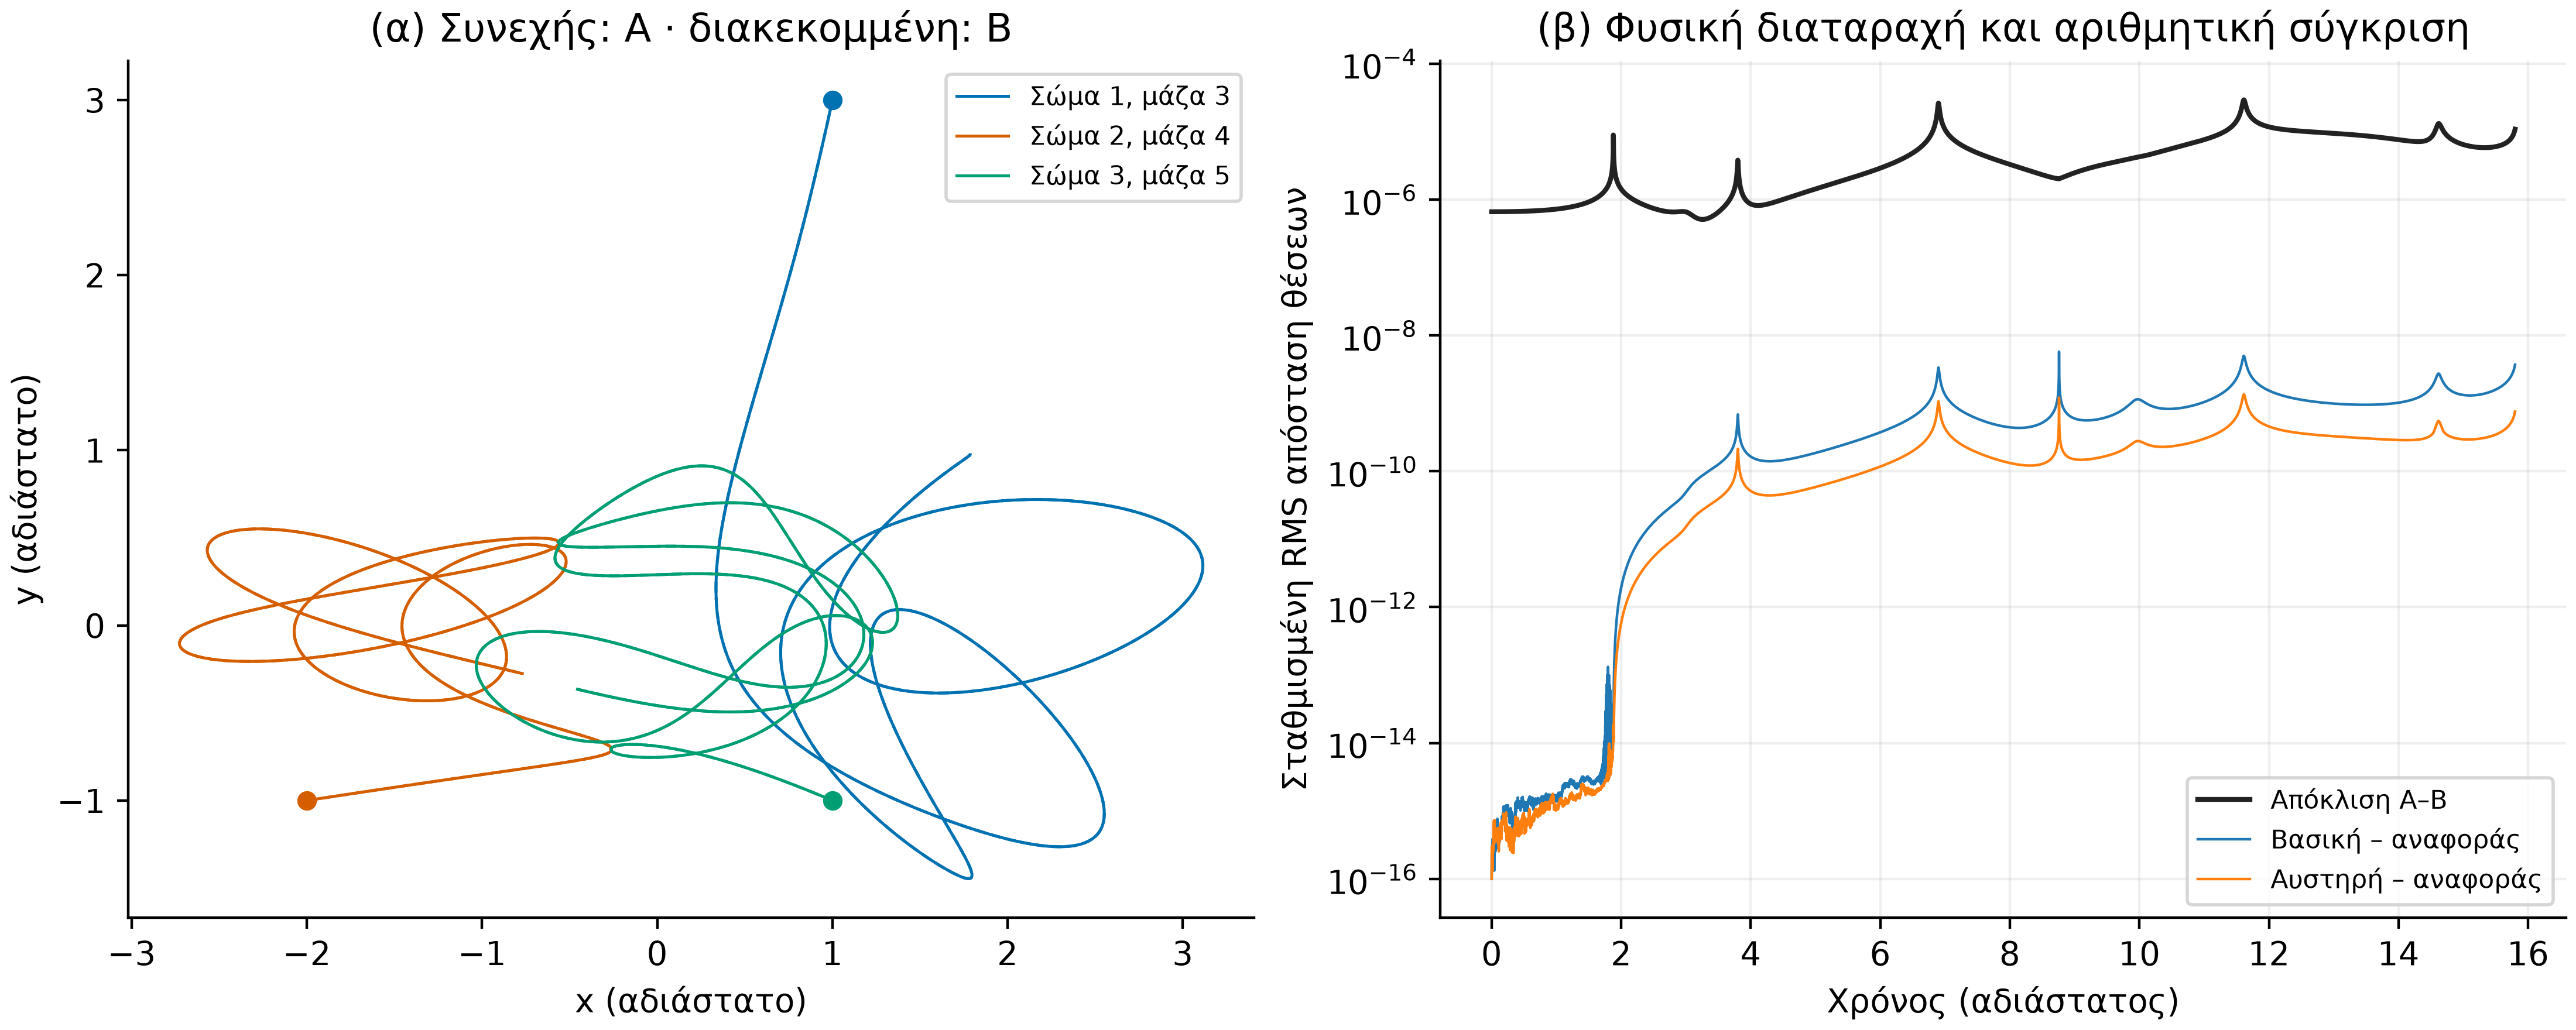

In [2]:
times, A, B, checks = run()
print(json.dumps(checks, ensure_ascii=False, indent=2))
from IPython.display import display, Image
display(Image(filename='results/publication.png'))

## Διαβάζουμε το αποτέλεσμα προσεκτικά
Η μαύρη καμπύλη δείχνει την απόσταση των διαφορετικών αρχικών καταστάσεων. Οι δύο άλλες δείχνουν διαφορές της ίδιας αρχικής κατάστασης όταν αλλάζουν οι ανοχές (το μέγιστο για Α και Β). Είναι εκτιμήσεις σύγκλισης, όχι αυστηρά άνω φράγματα του σφάλματος: οι λύσεις χρησιμοποιούν την ίδια μέθοδο και την ίδια αριθμητική κινητής υποδιαστολής.

Το αυτόματο κριτήριο απαιτεί: σχετική ενεργειακή μεταβολή κάτω από $10^{-7}$, απόλυτη μεταβολή ορμής και στροφορμής κάτω από $10^{-8}$ σε κάθε εκτέλεση, αύξηση της τελικής απόκλισης πάνω από 10 φορές, απόκλιση πάνω από 100 φορές το άθροισμα των δύο διαφορών σύγκλισης σε κάθε δειγματοληπτημένο χρόνο, και μείωση της μέγιστης διαφοράς με την αυστηρότερη ανοχή. Αυτά είναι κριτήρια καταλληλότητας της επίδειξης, όχι θεώρημα χάους.

Η αύξηση της απόστασης είναι ένδειξη ευαίσθητης εξάρτησης στο συγκεκριμένο χρονικό διάστημα. Μια απόκλιση μπορεί επίσης να προκύψει από διαφορά φάσης ή διαφορετικές διατηρούμενες ποσότητες. Δεν υπολογίζουμε εκθέτη Lyapunov: η κλίση μιας καμπύλης $\log D(t)$ χωρίς εφαπτομενικές εξισώσεις ή συστηματική επανακανονικοποίηση δεν είναι τεκμηριωμένη ασυμπτωτική εκτίμησή του. Δεν αποδεικνύουμε χάος ούτε γενικεύουμε σε όλες τις τροχιές.

### Ερωτήσεις για την τάξη
1. Γιατί η μετατόπιση του δεύτερου σώματος είναι $-3\epsilon/4$;
2. Πώς διαφέρει ο έλεγχος ενέργειας από τον έλεγχο σύγκλισης;
3. Επαναλάβετε με $\epsilon=10^{-5}$ και συγκρίνετε $D(t)/D(0)$. Μην αλλάξετε συγχρόνως άλλες παραμέτρους.
4. Γιατί μια ευθεία σε ημιλογαριθμικό γράφημα μικρής διάρκειας δεν αρκεί για απόδειξη χάους;

### Πηγές
- [Szebehely & Peters (1967), Complete Solution of a General Problem of Three Bodies](https://adsabs.harvard.edu/pdf/1967AJ.....72..876S): διάταξη Burrau και στενές προσεγγίσεις.
- [Chenciner & Montgomery (2000), οκτάσχημη περιοδική λύση](https://arxiv.org/abs/math/0011268): παράδειγμα περιοδικής κίνησης.
- [SciPy, solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html): DOP853, ανοχές, πυκνή έξοδος και γεγονότα.
